In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Online Retail.xlsx")

df = df.drop_duplicates()

df = df.dropna(
    subset=["CustomerID"]
)

df["Revenue"] = (
    df["Quantity"] *
    df["UnitPrice"]
)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## Step 2: Top Revenue Products
Kaunsa product sabse zyada revenue generate kar raha hai?

In [2]:
top_products = (

    df.groupby(
        "Description"
    )["Revenue"]

    .sum()

    .sort_values(
        ascending=False
    )

    .head(10)

)

top_products

Description
REGENCY CAKESTAND 3 TIER              132567.70
WHITE HANGING HEART T-LIGHT HOLDER     93767.80
JUMBO BAG RED RETROSPOT                83056.52
PARTY BUNTING                          67628.43
POSTAGE                                66710.24
ASSORTED COLOUR BIRD ORNAMENT          56331.91
RABBIT NIGHT LIGHT                     51042.84
CHILLI LIGHTS                          45915.41
PAPER CHAIN KIT 50'S CHRISTMAS         41423.78
PICNIC BASKET WICKER 60 PIECES         39619.50
Name: Revenue, dtype: float64

### Visualization



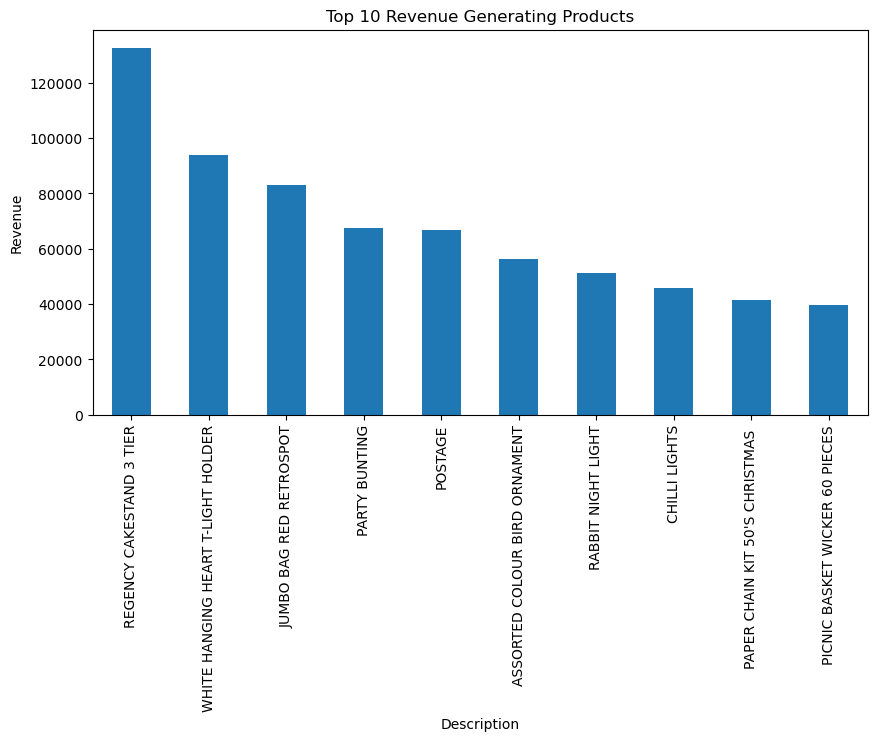

In [3]:
plt.figure(figsize=(10,5))

top_products.plot(
    kind="bar"
)

plt.title(
    "Top 10 Revenue Generating Products"
)

plt.ylabel(
    "Revenue"
)

plt.show()

### Step 3: Top Countries By Revenue

In [4]:
top_countries = (

    df.groupby(
        "Country"
    )["Revenue"]

    .sum()

    .sort_values(
        ascending=False
    )

    .head(10)

)

top_countries

Country
United Kingdom    6747156.154
Netherlands        284661.540
EIRE               250001.780
Germany            221509.470
France             196626.050
Australia          137009.770
Switzerland         55739.400
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Revenue, dtype: float64

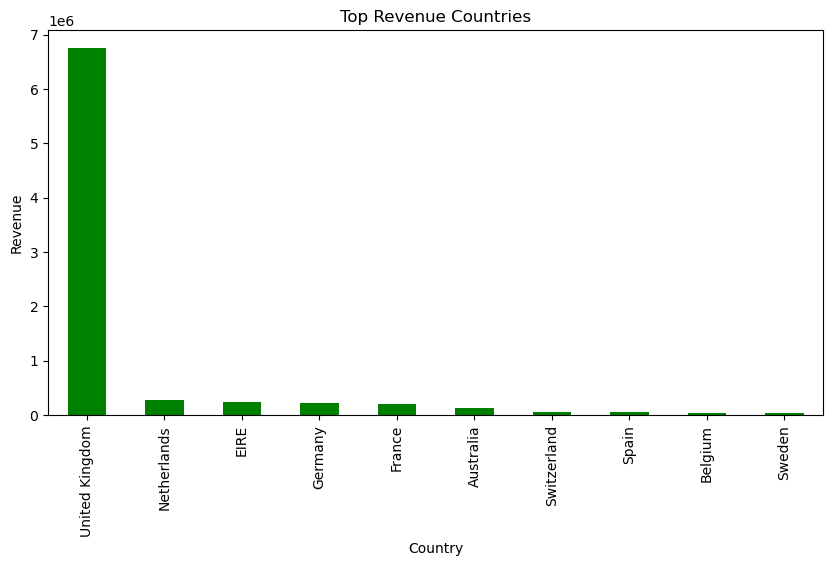

In [5]:
plt.figure(figsize=(10,5))

top_countries.plot(
    kind="bar",
    color="green"
)

plt.title(
    "Top Revenue Countries"
)

plt.ylabel(
    "Revenue"
)

plt.show()

#### Step 4: Monthly Sales Trend

In [6]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

df["Month"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
)

##### Monthly Revenue

In [7]:
monthly_sales = (

    df.groupby(
        "Month"
    )["Revenue"]

    .sum()
)

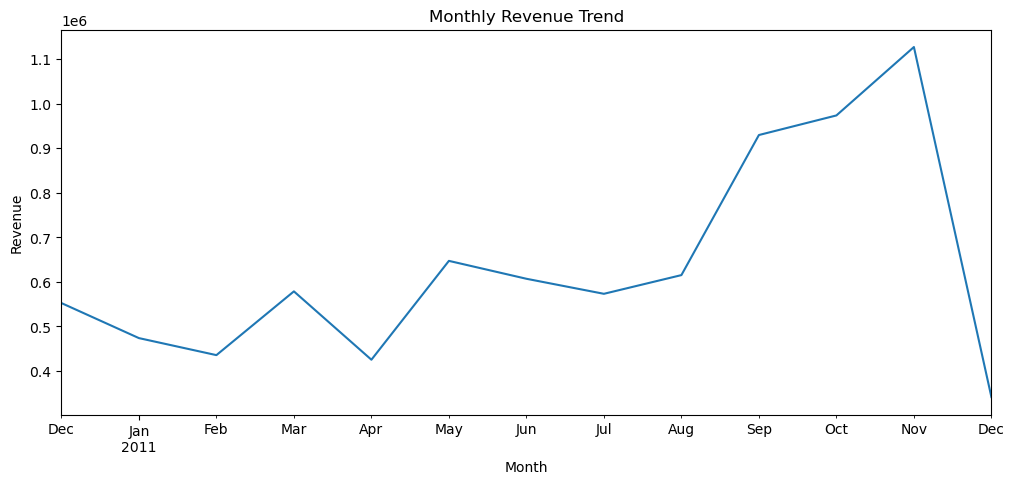

In [8]:
plt.figure(figsize=(12,5))

monthly_sales.plot()

plt.title(
    "Monthly Revenue Trend"
)

plt.ylabel(
    "Revenue"
)

plt.show()

#### Step 5: Top Customers

In [9]:
top_customers = (

    df.groupby(
        "CustomerID"
    )["Revenue"]

    .sum()

    .sort_values(
        ascending=False
    )

    .head(10)

)

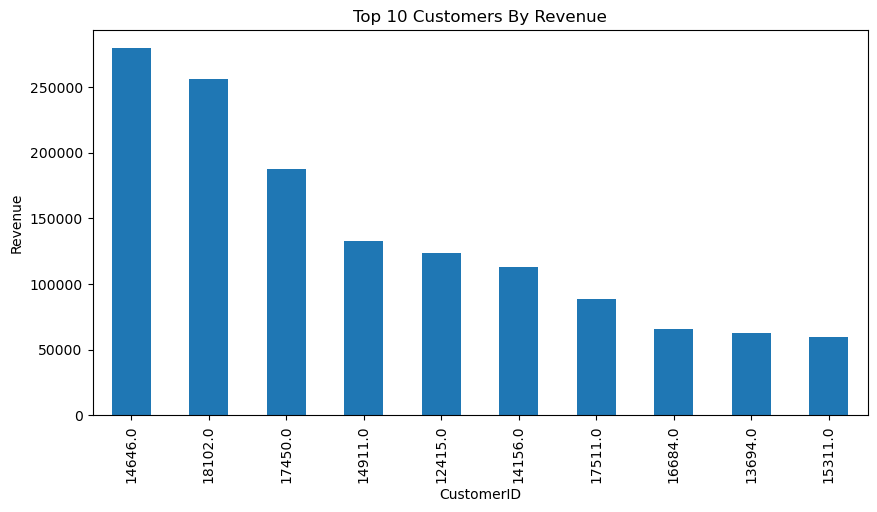

In [10]:
plt.figure(figsize=(10,5))

top_customers.plot(
    kind="bar"
)

plt.title(
    "Top 10 Customers By Revenue"
)

plt.ylabel(
    "Revenue"
)

plt.show()

## Business Insights

### Revenue

- A small number of products generate most of the revenue.

### Country Analysis

- Certain countries contribute significantly more revenue than others.

### Customer Analysis

- A small group of customers contributes a large share of total sales.

### Sales Trend

- Monthly sales trends help identify peak business periods and seasonality.

These insights can help improve inventory planning, marketing strategy and customer retention.